# 03 — Calibration and three-way decision policy

Answers RQ2 by reconstructing held-out discrimination, calibration and the approve–abstain–investigate policy from saved predictions and validation-derived thresholds.

**Reproducibility rule:** outputs below are generated from the untouched held-out test set or from validation/CV reports; no test result is used to fit the model or choose thresholds.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, roc_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
PUB = ROOT / "publication"
FIGURES = PUB / "figures"
TABLES = PUB / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GOLD, RED, GREEN, GREY = "#1f4e79", "#d89b2b", "#b03a2e", "#2e7d32", "#6b7280"

In [2]:
pred = pd.read_csv(ROOT / "reports" / "held_out_test_predictions.csv")
cal = pd.read_csv(ROOT / "reports" / "calibration_curve.csv")
thresholds = json.loads((ROOT / "reports" / "decision_thresholds.json").read_text())
metrics = json.loads((ROOT / "reports" / "test_metrics.json").read_text())
thresholds, metrics

({'approve_below': 0.04696095836326292,
  'investigate_at_or_above': 0.09295608680621309,
  'target_negative_predictive_value': 0.99,
  'selection_dataset': 'validation'},
 {'threshold': 0.09295608680621309,
  'accuracy': 0.7603761348897535,
  'precision': 0.16626506024096385,
  'recall': 0.745945945945946,
  'specificity': 0.7612969989651605,
  'f1': 0.27192118226600986,
  'f2': 0.4394904458598726,
  'roc_auc': 0.8432562952742325,
  'pr_auc': 0.2558651283448916,
  'brier_score': 0.04997766155602519,
  'tn': 2207,
  'fp': 692,
  'fn': 47,
  'tp': 138,
  'positive_prediction_rate': 0.2691309987029831})

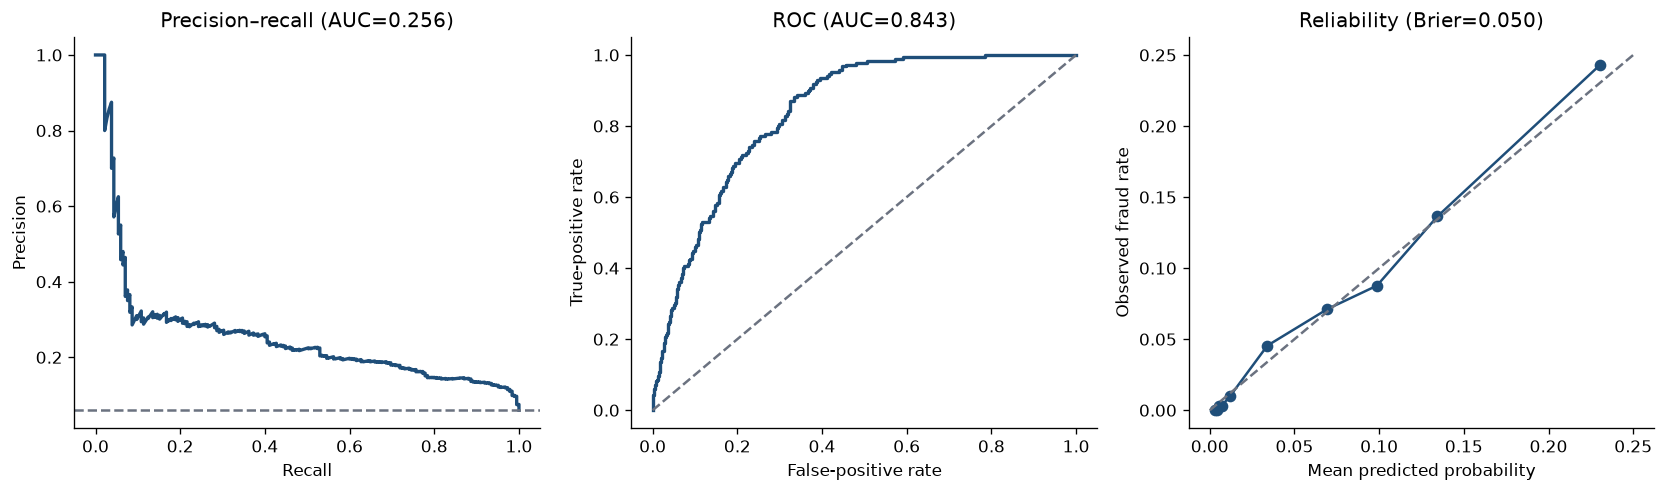

In [3]:
y, p = pred["actual_fraud"].to_numpy(), pred["fraud_probability"].to_numpy()
precision, recall, _ = precision_recall_curve(y, p)
fpr, tpr, _ = roc_curve(y, p)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(recall, precision, color=BLUE, lw=2); axes[0].axhline(y.mean(), ls="--", color=GREY); axes[0].set(xlabel="Recall", ylabel="Precision", title=f"Precision–recall (AUC={metrics['pr_auc']:.3f})")
axes[1].plot(fpr, tpr, color=BLUE, lw=2); axes[1].plot([0,1],[0,1], ls="--", color=GREY); axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate", title=f"ROC (AUC={metrics['roc_auc']:.3f})")
axes[2].plot(cal["mean_predicted_probability"], cal["observed_fraud_rate"], marker="o", color=BLUE); axes[2].plot([0,.25],[0,.25], ls="--", color=GREY); axes[2].set(xlabel="Mean predicted probability", ylabel="Observed fraud rate", title=f"Reliability (Brier={metrics['brier_score']:.3f})")
fig.tight_layout(); fig.savefig(FIGURES / "figure_03_discrimination_calibration.png", bbox_inches="tight"); plt.show()

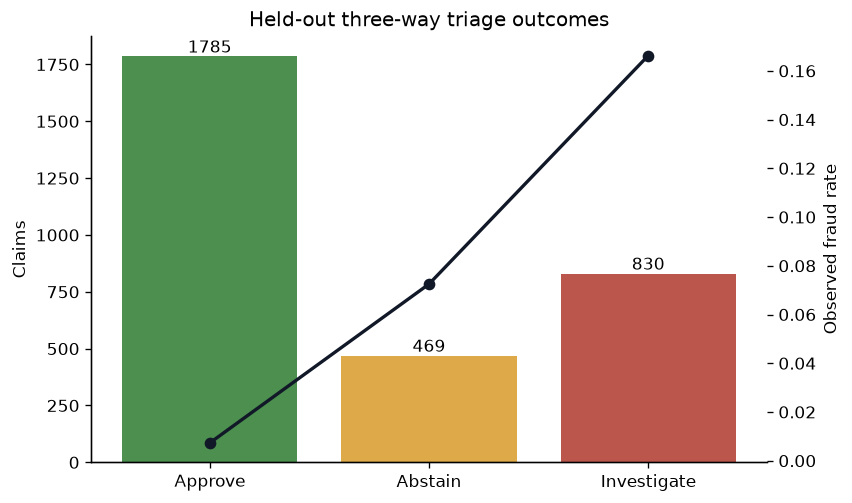

In [4]:
decision = pd.read_csv(ROOT / "reports" / "decision_policy_test_summary.csv")
decision.to_csv(TABLES / "table_05_decision_policy.csv", index=False)
(TABLES / "table_05_decision_policy.tex").write_text(decision.to_latex(index=False, escape=True, float_format="%.4f"), encoding="utf-8")

order = ["approve", "abstain", "investigate"]
d = decision.set_index("decision").loc[order]
fig, ax1 = plt.subplots(figsize=(7.2, 4.3))
x = np.arange(len(order)); bars = ax1.bar(x, d["claims"], color=[GREEN, GOLD, RED], alpha=.86)
ax1.set_xticks(x, [s.title() for s in order]); ax1.set_ylabel("Claims"); ax1.set_title("Held-out three-way triage outcomes")
ax2 = ax1.twinx(); ax2.plot(x, d["observed_fraud_rate"], color="#111827", marker="o", lw=2); ax2.set_ylabel("Observed fraud rate")
for b, n in zip(bars, d["claims"]): ax1.text(b.get_x()+b.get_width()/2, n, str(n), ha="center", va="bottom")
fig.tight_layout(); fig.savefig(FIGURES / "figure_04_decision_policy.png", bbox_inches="tight"); plt.show()

### Decision function used by the prototype

For fold (k), a raw model score (z_k(x)) is sigmoid-calibrated as

\[
p_k(x)=\frac{1}{1+\exp(a_k z_k(x)+b_k)},\qquad
\hat p(x)=\frac{1}{K}\sum_{k=1}^{K}p_k(x),\quad K=5.
\]

The operational action is

\[
d(x)=\begin{cases}
\mathrm{approve},&\hat p(x)<\tau_A,\\
\mathrm{abstain},&\tau_A\leq\hat p(x)<\tau_I,\\
\mathrm{investigate},&\hat p(x)\geq\tau_I,
\end{cases}
\]

where \(\tau_A=0.0469609584\) is the largest validation threshold satisfying \(\mathrm{NPV}\geq0.99\), and \(\tau_I=0.0929560868\) maximizes validation \(F_2=5PR/(4P+R)\). No threshold was selected on the test set.